# CVRP: Exact MILP vs Heuristic

In this notebook we solve the Capacitated Vehicle Routing Problem (CVRP) in two
ways and compare them. The first is an exact MILP model (the MTZ formulation)
solved with CBC. The second is a heuristic: a greedy construction followed by
Simulated Annealing.

All the actual code lives in `src/`. The notebook just loads the instances, runs
the solvers and shows the results, so everything here can be re-run from
scratch.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# project root = the folder that contains src/ and data/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import common
from loader import load_cvrplib
from model_milp import build_model, solve

DATA = ROOT / "data" / "instances"
print("project root:", ROOT)
print("instances:", sorted(p.name for p in DATA.glob("*.vrp")))


project root: /Users/nisalgangana/Documents/SLIIT/Y1S2/Optimization/optimization-assignment-cvrp
instances: ['A-n32-k5.vrp', 'A-n45-k6.vrp', 'A-n80-k10.vrp', 'E-n22-k4.vrp', 'P-n16-k8.vrp']


## 1. Data

We use five benchmark instances from CVRPLIB (sets P, E and A). We chose these
because each one has a published optimal cost, so we can measure exactly how far
each method is from the best possible answer. Distances are Euclidean, rounded to
the nearest integer, which is the same convention the published optima use.

Besides the basic details of each instance, the table below shows two extra
columns:

- **min vehicles** = ⌈total demand / Q⌉, the smallest number of trucks that
  could carry everything
- **fill rate** = total demand / (K · Q), how full the whole fleet is


In [2]:
NAMES = ["P-n16-k8", "E-n22-k4", "A-n32-k5", "A-n45-k6", "A-n80-k10"]
instances = {name: load_cvrplib(DATA / f"{name}.vrp") for name in NAMES}

rows = []
for name, inst in instances.items():
    total = int(inst.demand.sum())
    rows.append({
        "instance": name,
        "customers (n)": inst.n_customers,
        "vehicles (K)": inst.n_vehicles,
        "capacity (Q)": inst.capacity,
        "total demand": total,
        "min vehicles": math.ceil(total / inst.capacity),
        "fill rate": round(total / (inst.n_vehicles * inst.capacity), 2),
        "optimum": inst.optimum,
    })
data_table = pd.DataFrame(rows).set_index("instance")
data_table


,customers (n),vehicles (K),capacity (Q),total demand,min vehicles,fill rate,optimum
instance,,,,,,,
P-n16-k8,15,8,35,246,8,0.88,450
E-n22-k4,21,4,6000,22500,4,0.94,375
A-n32-k5,31,5,100,410,5,0.82,784
A-n45-k6,44,6,100,593,6,0.99,944
A-n80-k10,79,10,100,942,10,0.94,1763


A few things stand out:

- The instances range from 15 to 79 customers, which lets us see how each method
  behaves as the problem grows.
- In every instance, the minimum number of vehicles is exactly K. There is no
  spare truck, so every route has to be packed carefully.
- The fill rate is between 0.82 and 0.99. In A-n45-k6 the fleet is 99% full,
  so the capacity constraint is very tight. This is one reason these instances
  are hard to solve.

The plot below shows the smallest instance, P-n16-k8. The red square is the
depot, and the size of each dot shows the customer's demand.


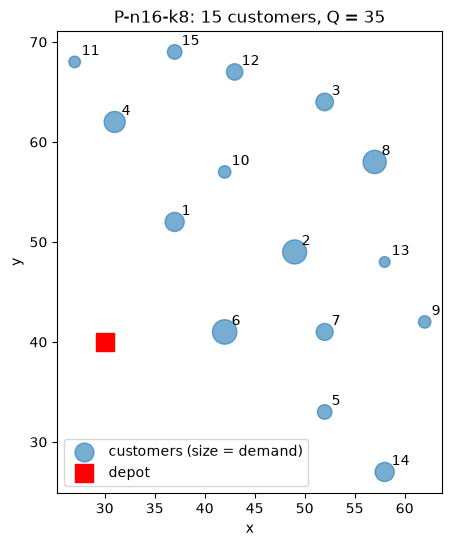

In [3]:
inst = instances["P-n16-k8"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(inst.coords[1:, 0], inst.coords[1:, 1], s=inst.demand[1:] * 10,
           alpha=0.6, label="customers (size = demand)")
ax.scatter(*inst.coords[0], marker="s", s=150, color="red", label="depot")
for i in inst.customers:
    ax.annotate(str(i), inst.coords[i], textcoords="offset points", xytext=(5, 5))
ax.set_title(f"{inst.name}: {inst.n_customers} customers, Q = {inst.capacity}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.set_aspect("equal")
plt.show()
